In [1]:
import os
import json
import time
import joblib
import logging
import warnings

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from sklearn.metrics import (
    average_precision_score, roc_auc_score, precision_recall_curve, confusion_matrix, precision_score, recall_score
)

import xgboost as xgb
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
import shap
import mlflow
import mlflow.xgboost

warnings.filterwarnings('ignore')
logging.basicConfig(level=logging.INFO, format="%(asctime)s - %(levelname)s - %(message)s", force=True)
logger = logging.getLogger(__name__)
logging.getLogger('alembic').setLevel(logging.WARNING)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)

DATA_DIR = Path(os.environ.get('DATA_DIR', '.'))
FAST = os.environ.get('FAST') == '1'
MONTHLY_BUDGET = 1000
RANDOM_AUDIT = 50
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

for folder in ['artifacts', 'scored', 'verdicts']:
    os.makedirs(folder, exist_ok=True)

In [2]:
train_df = pd.read_csv(DATA_DIR / 'fraudTrain.csv', index_col=0)
test_df = pd.read_csv(DATA_DIR / 'fraudTest.csv', index_col=0)

if FAST:
    train_df = train_df.sample(frac=0.2, random_state=RANDOM_STATE)
    test_df = test_df.sample(frac=0.2, random_state=RANDOM_STATE)

train_df['ts'] = pd.to_datetime(train_df['trans_date_trans_time'])
test_df['ts'] = pd.to_datetime(test_df['trans_date_trans_time'])

logger.info(f'Train shape: {train_df.shape} | {train_df['ts'].min()} to {train_df['ts'].max()}')
logger.info(f'Test shape: {test_df.shape} | {test_df['ts'].min()} to {test_df['ts'].max()}')
logger.info(f'Fraud Distribution (train):\n{train_df['is_fraud'].value_counts()}')
logger.info(f'Fraud Percentage: train {train_df['is_fraud'].mean() * 100:.3f}% | test {test_df['is_fraud'].mean() * 100:.3f}%')
logger.info(f'Missing Values: {train_df.isnull().sum().sum()}')
logger.info(f'Cards in test not seen in train: {len(set(test_df['cc_num']) - set(train_df['cc_num']))}')

train_df.head()

2026-11-02 15:03:17,106 - INFO - Train shape: (1296675, 23) | 2019-01-01 00:00:18 to 2020-06-21 12:13:37
2026-11-02 15:03:17,108 - INFO - Test shape: (555719, 23) | 2020-06-21 12:14:25 to 2020-12-31 23:59:34
2026-11-02 15:03:17,113 - INFO - Fraud Distribution (train):
is_fraud
0    1289169
1       7506
Name: count, dtype: int64
2026-11-02 15:03:17,115 - INFO - Fraud Percentage: train 0.579% | test 0.386%
2026-11-02 15:03:17,394 - INFO - Missing Values: 0
2026-11-02 15:03:17,504 - INFO - Cards in test not seen in train: 16


,trans_date_trans_time,cc_num,merchant,category,amt,first,last,gender,street,city,...,long,city_pop,job,dob,trans_num,unix_time,merch_lat,merch_long,is_fraud,ts
0,2019-01-01 00:00:18,2703186189652095,"fraud_Rippin, Kub and Mann",misc_net,4.97,Jennifer,Banks,F,561 Perry Cove,Moravian Falls,...,-81.1781,3495,"Psychologist, counselling",1988-03-09,0b242abb623afc578575680df30655b9,1325376018,36.011293,-82.048315,0,2019-01-01 00:00:18
1,2019-01-01 00:00:44,630423337322,"fraud_Heller, Gutmann and Zieme",grocery_pos,107.23,Stephanie,Gill,F,43039 Riley Greens Suite 393,Orient,...,-118.2105,149,Special educational needs teacher,1978-06-21,1f76529f8574734946361c461b024d99,1325376044,49.159047,-118.186462,0,2019-01-01 00:00:44
2,2019-01-01 00:00:51,38859492057661,fraud_Lind-Buckridge,entertainment,220.11,Edward,Sanchez,M,594 White Dale Suite 530,Malad City,...,-112.2620,4154,Nature conservation officer,1962-01-19,a1a22d70485983eac12b5b88dad1cf95,1325376051,43.150704,-112.154481,0,2019-01-01 00:00:51
3,2019-01-01 00:01:16,3534093764340240,"fraud_Kutch, Hermiston and Farrell",gas_transport,45.00,Jeremy,White,M,9443 Cynthia Court Apt. 038,Boulder,...,-112.1138,1939,Patent attorney,1967-01-12,6b849c168bdad6f867558c3793159a81,1325376076,47.034331,-112.561071,0,2019-01-01 00:01:16
4,2019-01-01 00:03:06,375534208663984,fraud_Keeling-Crist,misc_pos,41.96,Tyler,Garcia,M,408 Bradley Rest,Doe Hill,...,-79.4629,99,Dance movement psychotherapist,1986-03-28,a41d7549acf90789359a9aa5346dcb46,1325376186,38.674999,-78.632459,0,2019-01-01 00:03:06


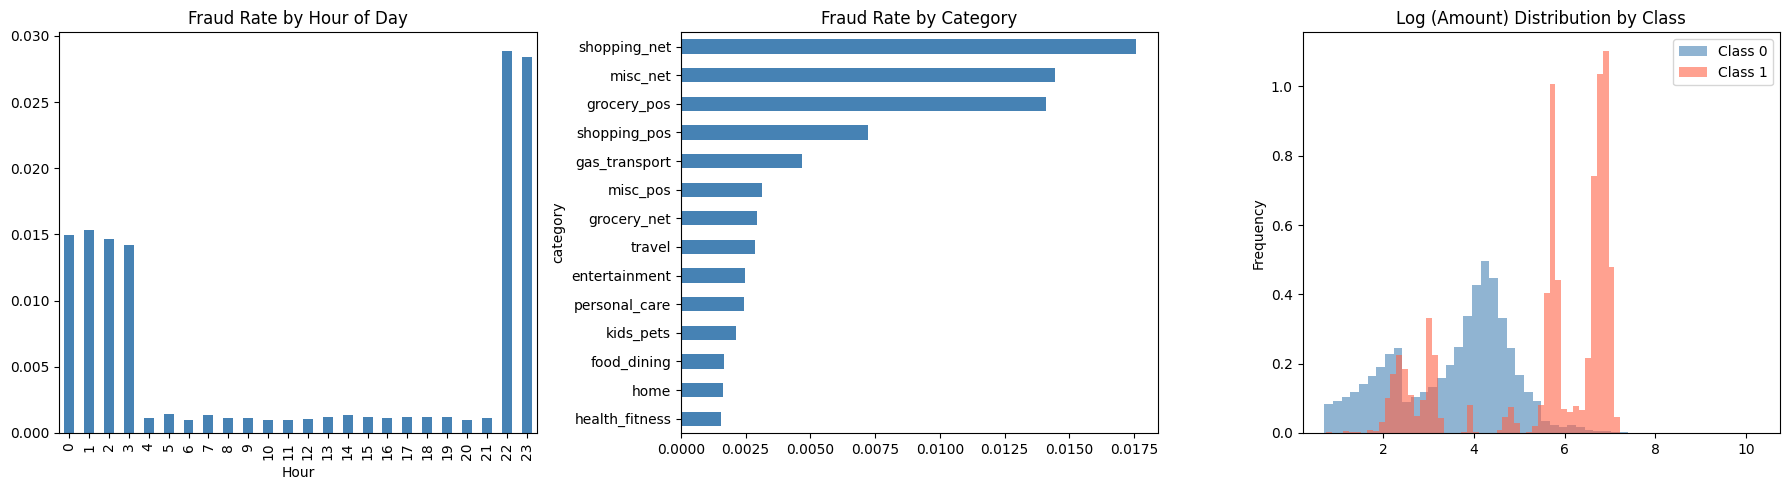

2026-11-02 15:03:18,094 - INFO - Fraud transaction stats:
count    7506.000000
mean      531.320092
std       390.560070
min         1.060000
25%       245.662500
50%       396.505000
75%       900.875000
max      1376.040000
Name: amt, dtype: float64
2026-11-02 15:03:18,266 - INFO - Legit transaction stats:
count    1.289169e+06
mean     6.766711e+01
std      1.540080e+02
min      1.000000e+00
25%      9.610000e+00
50%      4.728000e+01
75%      8.254000e+01
max      2.894890e+04
Name: amt, dtype: float64


In [3]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

train_df.groupby(train_df['ts'].dt.hour)['is_fraud'].mean().plot(kind='bar', ax=axes[0], color='steelblue')
axes[0].set_title('Fraud Rate by Hour of Day')
axes[0].set_xlabel('Hour')

train_df.groupby('category')['is_fraud'].mean().sort_values().plot(kind='barh', ax=axes[1], color='steelblue')
axes[1].set_title('Fraud Rate by Category')

for label, color in zip([0, 1], ['steelblue', 'tomato']):
    train_df[train_df['is_fraud'] == label]['amt'].apply(np.log1p).plot(
        kind='hist', bins=50, alpha=0.6, ax=axes[2], color=color, label=f'Class {label}', density=True
    )
axes[2].set_title('Log (Amount) Distribution by Class')
axes[2].legend()

plt.tight_layout()
plt.show()

logger.info(f'Fraud transaction stats:\n{train_df[train_df['is_fraud'] == 1]['amt'].describe()}')
logger.info(f'Legit transaction stats:\n{train_df[train_df['is_fraud'] == 0]['amt'].describe()}')

In [4]:
train_df['split'] = 'train'
test_df['split'] = 'test'
df = pd.concat([train_df, test_df]).sort_values(['cc_num', 'ts']).reset_index(drop=True)

df['hour'] = df['ts'].dt.hour
df['dow'] = df['ts'].dt.dayofweek
df['is_night'] = ((df['hour'] >= 22) | (df['hour'] < 4)).astype(int)
df['age'] = ((df['ts'] - pd.to_datetime(df['dob'])).dt.days / 365.25).round(1)
df['gender_m'] = (df['gender'] == 'M').astype(int)
df['log_city_pop'] = np.log1p(df['city_pop'])
df['log_amt'] = np.log1p(df['amt'])

lat1, lon1, lat2, lon2 = map(np.radians, [df['lat'], df['long'], df['merch_lat'], df['merch_long']])
a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
df['dist_km'] = 2 * 6371 * np.arcsin(np.sqrt(a))

logger.info('Time, customer and distance features created')

2026-11-02 15:03:20,010 - INFO - Time, customer and distance features created


In [5]:
card_group = df.groupby('cc_num')
card_prev_mean = (card_group['amt'].cumsum() - df['amt']) / card_group.cumcount().replace(0, np.nan)
df['amt_vs_card_mean'] = (df['amt'] / card_prev_mean).fillna(1)

card_cat_group = df.groupby(['cc_num', 'category'])
card_cat_prev_mean = (card_cat_group['amt'].cumsum() - df['amt']) / card_cat_group.cumcount().replace(0, np.nan)
df['amt_vs_card_cat_mean'] = (df['amt'] / card_cat_prev_mean).fillna(1)

rolling_group = df.set_index('ts').groupby('cc_num')['amt']
df['n_1h'] = rolling_group.rolling('1h').count().values - 1
df['n_24h'] = rolling_group.rolling('24h').count().values - 1
df['n_7d'] = rolling_group.rolling('7D').count().values - 1
df['amt_24h'] = rolling_group.rolling('24h').sum().values - df['amt'].values
df['secs_since_prev'] = card_group['unix_time'].diff().fillna(7 * 86400).clip(upper=7 * 86400)

categories = sorted(df[df['split'] == 'train']['category'].unique())
for cat in categories:
    df[f'cat_{cat}'] = (df['category'] == cat).astype(int)

FEATURES = [
    'hour', 'dow', 'is_night', 'age', 'gender_m', 'log_city_pop', 'log_amt', 'dist_km', 'amt',
    'amt_vs_card_mean', 'amt_vs_card_cat_mean', 'n_1h', 'n_24h', 'n_7d', 'amt_24h', 'secs_since_prev'
] + [f'cat_{cat}' for cat in categories]

logger.info(f'Card history and velocity features created | {len(FEATURES)} features total')
logger.info(f'Median by class:\n{df[df['split'] == 'train'].groupby('is_fraud')[['is_night', 'amt_vs_card_mean', 'amt_vs_card_cat_mean', 'n_24h', 'amt_24h', 'dist_km']].median()}')

2026-11-02 15:03:23,599 - INFO - Card history and velocity features created | 30 features total
2026-11-02 15:03:24,037 - INFO - Median by class:
          is_night  amt_vs_card_mean  amt_vs_card_cat_mean  n_24h   amt_24h  \
is_fraud                                                                      
0              0.0          0.664867              0.828551    3.0   171.140   
1              1.0          5.163651              3.391272    4.0  1674.155   

            dist_km  
is_fraud             
0         78.233012  
1         77.931954  


In [6]:
train = df[df['split'] == 'train']
test = df[df['split'] == 'test'].sort_values('ts').reset_index(drop=True)

VAL_START = '2020-04-01'
fit = train[train['ts'] < VAL_START]
val = train[train['ts'] >= VAL_START]

X_fit, y_fit = fit[FEATURES], fit['is_fraud'].values
X_val, y_val = val[FEATURES], val['is_fraud'].values
X_test, y_test = test[FEATURES], test['is_fraud'].values

monthly_volume = train.groupby(train['ts'].dt.to_period('M')).size().mean()
BUDGET_FRAC = MONTHLY_BUDGET / monthly_volume

logger.info(f'Fit set: {X_fit.shape[0]} rows | Fraud: {y_fit.sum()} ({y_fit.mean() * 100:.3f}%)')
logger.info(f'Validation set: {X_val.shape[0]} rows | Fraud: {y_val.sum()} ({y_val.mean() * 100:.3f}%)')
logger.info(f'Test set: {X_test.shape[0]} rows | Fraud: {y_test.sum()} ({y_test.mean() * 100:.3f}%)')
logger.info(f'Monthly volume: {monthly_volume:,.0f} | budget of {MONTHLY_BUDGET} = top {BUDGET_FRAC * 100:.2f}%')

2026-11-02 15:03:25,141 - INFO - Fit set: 1097693 rows | Fraud: 6343 (0.578%)
2026-11-02 15:03:25,142 - INFO - Validation set: 198982 rows | Fraud: 1163 (0.584%)
2026-11-02 15:03:25,143 - INFO - Test set: 555719 rows | Fraud: 2145 (0.386%)
2026-11-02 15:03:25,143 - INFO - Monthly volume: 72,038 | budget of 1000 = top 1.39%


In [7]:
def evaluate(y_true, probs, model_name):
    k = int(len(y_true) * BUDGET_FRAC)
    top_k = np.argsort(-probs)[:k]
    metrics = {
        'auc_pr': average_precision_score(y_true, probs),
        'auc_roc': roc_auc_score(y_true, probs),
        'precision_at_budget': y_true[top_k].mean(),
        'recall_at_budget': y_true[top_k].sum() / y_true.sum(),
    }
    logger.info(f'=== {model_name} ===')
    for key, value in metrics.items():
        logger.info(f'{key}: {value:.4f}')
    return metrics


scale_pos_weight = (y_fit == 0).sum() / (y_fit == 1).sum()

xgb_params = {
    'n_estimators': 2000,
    'max_depth': 6,
    'learning_rate': 0.05,
    'min_child_weight': 5,
    'subsample': 0.8,
    'colsample_bytree': 0.8,
    'scale_pos_weight': scale_pos_weight,
    'eval_metric': 'aucpr',
    'tree_method': 'hist',
    'early_stopping_rounds': 100,
    'random_state': RANDOM_STATE,
}

start = time.time()
xgb_model = xgb.XGBClassifier(device=DEVICE, **xgb_params)
xgb_model.fit(X_fit, y_fit, eval_set=[(X_val, y_val)], verbose=False)

xgb_val_probs = xgb_model.predict_proba(X_val)[:, 1]
xgb_test_probs = xgb_model.predict_proba(X_test)[:, 1]

logger.info(f'XGBoost trained in {time.time() - start:.0f}s | best iteration {xgb_model.best_iteration}')
xgb_val_metrics = evaluate(y_val, xgb_val_probs, 'XGBoost Validation')
xgb_test_metrics = evaluate(y_test, xgb_test_probs, 'XGBoost Test')

2026-11-02 15:03:31,817 - INFO - XGBoost trained in 7s | best iteration 1164
2026-11-02 15:03:31,895 - INFO - === XGBoost Validation ===
2026-11-02 15:03:31,895 - INFO - auc_pr: 0.9856
2026-11-02 15:03:31,896 - INFO - auc_roc: 0.9997
2026-11-02 15:03:31,896 - INFO - precision_at_budget: 0.4178
2026-11-02 15:03:31,896 - INFO - recall_at_budget: 0.9923
2026-11-02 15:03:32,072 - INFO - === XGBoost Test ===
2026-11-02 15:03:32,073 - INFO - auc_pr: 0.9769
2026-11-02 15:03:32,073 - INFO - auc_roc: 0.9994
2026-11-02 15:03:32,073 - INFO - precision_at_budget: 0.2759
2026-11-02 15:03:32,073 - INFO - recall_at_budget: 0.9921


In [8]:
class FeatureScaler:
    def __init__(self, X):
        self.mu = X.mean().values
        self.sd = np.where(X.std().values == 0, 1, X.std().values)

    def transform(self, X):
        return ((X.values - self.mu) / self.sd).astype('float32')

In [9]:
legit_mask = y_fit == 0
X_legit = X_fit[legit_mask]

scaler = FeatureScaler(X_legit)
X_legit_scaled = scaler.transform(X_legit)

X_legit_tensor = torch.from_numpy(X_legit_scaled)
train_dataset = TensorDataset(X_legit_tensor, X_legit_tensor)
train_loader = DataLoader(train_dataset, batch_size=4096, shuffle=True)

logger.info(f'Autoencoder trains on legit rows only: {X_legit_tensor.shape}')
logger.info(f'Batches per epoch: {len(train_loader)}')

2026-11-02 15:03:32,656 - INFO - Autoencoder trains on legit rows only: torch.Size([1091350, 30])
2026-11-02 15:03:32,657 - INFO - Batches per epoch: 267


In [10]:
class Autoencoder(nn.Module):
    def __init__(self, input_dim):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 24),
            nn.ReLU(),
            nn.Linear(24, 8)
        )

        self.decoder = nn.Sequential(
            nn.Linear(8, 24),
            nn.ReLU(),
            nn.Linear(24, 64),
            nn.ReLU(),
            nn.Linear(64, input_dim)
        )

    def forward(self, x):
        encoded = self.encoder(x)
        decoded = self.decoder(encoded)
        return decoded


input_dim = X_legit_tensor.shape[1]
autoencoder = Autoencoder(input_dim).to(DEVICE)
print(autoencoder)

Autoencoder(
  (encoder): Sequential(
    (0): Linear(in_features=30, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=24, bias=True)
    (3): ReLU()
    (4): Linear(in_features=24, out_features=8, bias=True)
  )
  (decoder): Sequential(
    (0): Linear(in_features=8, out_features=24, bias=True)
    (1): ReLU()
    (2): Linear(in_features=24, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=30, bias=True)
  )
)


2026-11-02 15:03:41,396 - INFO - Epoch 1/20, loss: 0.571012
2026-11-02 15:04:11,375 - INFO - Epoch 5/20, loss: 0.119667
2026-11-02 15:04:49,018 - INFO - Epoch 10/20, loss: 0.089941
2026-11-02 15:05:26,569 - INFO - Epoch 15/20, loss: 0.067490
2026-11-02 15:06:07,645 - INFO - Epoch 20/20, loss: 0.057279
2026-11-02 15:06:07,645 - INFO - Autoencoder trained in 154s


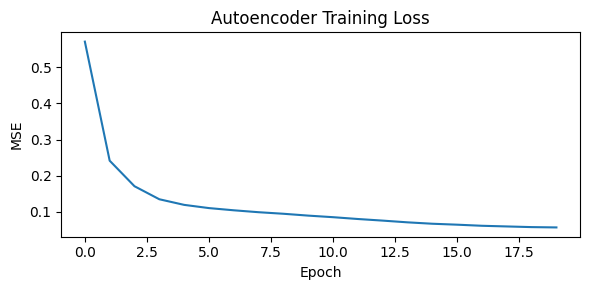

In [11]:
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(autoencoder.parameters(), lr=1e-3)

epochs = 3 if FAST else 20
history = []

start = time.time()
for epoch in range(epochs):
    autoencoder.train()
    epoch_loss = 0

    for batch_input, batch_target in train_loader:
        batch_input = batch_input.to(DEVICE)
        batch_target = batch_target.to(DEVICE)

        output = autoencoder(batch_input)
        loss = criterion(output, batch_target)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        epoch_loss += loss.item() * len(batch_input)

    avg_loss = epoch_loss / len(train_loader.dataset)
    history.append(avg_loss)

    if (epoch + 1) % 5 == 0 or epoch == 0:
        logger.info(f'Epoch {epoch + 1}/{epochs}, loss: {avg_loss:.6f}')

logger.info(f'Autoencoder trained in {time.time() - start:.0f}s')

plt.figure(figsize=(6, 3))
plt.plot(history)
plt.xlabel('Epoch')
plt.ylabel('MSE')
plt.title('Autoencoder Training Loss')
plt.tight_layout()
plt.show()

2026-11-02 15:06:08,118 - INFO - Normal - Mean: 0.0597, Median: 0.0368
2026-11-02 15:06:08,119 - INFO - Fraud - Mean: 0.7032, Median: 0.5436
2026-11-02 15:06:08,119 - INFO - Fraud/Normal ratio: 11.8x


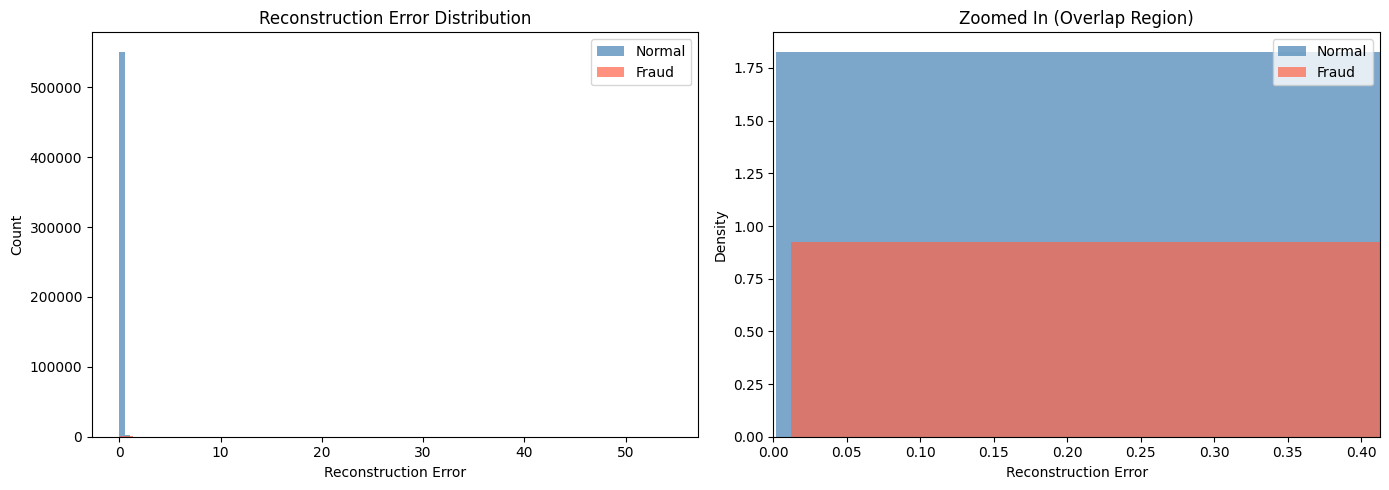

2026-11-02 15:06:08,626 - INFO - === Autoencoder Test ===
2026-11-02 15:06:08,627 - INFO - auc_pr: 0.2296
2026-11-02 15:06:08,627 - INFO - auc_roc: 0.9545
2026-11-02 15:06:08,627 - INFO - precision_at_budget: 0.1829
2026-11-02 15:06:08,628 - INFO - recall_at_budget: 0.6578


In [12]:
def reconstruction_error(X):
    autoencoder.eval()
    X_tensor = torch.from_numpy(scaler.transform(X))
    errors = []
    with torch.no_grad():
        for i in range(0, len(X_tensor), 65536):
            batch = X_tensor[i:i + 65536].to(DEVICE)
            reconstructed = autoencoder(batch)
            mse_per_sample = torch.mean((batch - reconstructed) ** 2, dim=1)
            errors.append(mse_per_sample.cpu().numpy())
    return np.concatenate(errors)


ae_fit_err = reconstruction_error(X_fit)
ae_val_err = reconstruction_error(X_val)
ae_test_err = reconstruction_error(X_test)

normal_errors = ae_test_err[y_test == 0]
fraud_errors = ae_test_err[y_test == 1]

logger.info(f'Normal - Mean: {normal_errors.mean():.4f}, Median: {np.median(normal_errors):.4f}')
logger.info(f'Fraud - Mean: {fraud_errors.mean():.4f}, Median: {np.median(fraud_errors):.4f}')
logger.info(f'Fraud/Normal ratio: {fraud_errors.mean() / normal_errors.mean():.1f}x')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(normal_errors, bins=100, alpha=0.7, label='Normal', color='steelblue')
axes[0].hist(fraud_errors, bins=50, alpha=0.7, label='Fraud', color='tomato')
axes[0].set_xlabel('Reconstruction Error')
axes[0].set_ylabel('Count')
axes[0].set_title('Reconstruction Error Distribution')
axes[0].legend()

axes[1].hist(normal_errors, bins=100, alpha=0.7, label='Normal', color='steelblue', density=True)
axes[1].hist(fraud_errors, bins=50, alpha=0.7, label='Fraud', color='tomato', density=True)
axes[1].set_xlabel('Reconstruction Error')
axes[1].set_ylabel('Density')
axes[1].set_title('Zoomed In (Overlap Region)')
axes[1].set_xlim(0, np.quantile(ae_test_err, 0.99))
axes[1].legend()

plt.tight_layout()
plt.show()

ae_test_metrics = evaluate(y_test, ae_test_err, 'Autoencoder Test')

In [13]:
X_fit_ae = X_fit.assign(ae_err=ae_fit_err)
X_val_ae = X_val.assign(ae_err=ae_val_err)
X_test_ae = X_test.assign(ae_err=ae_test_err)

start = time.time()
xgb_ae_model = xgb.XGBClassifier(device=DEVICE, **xgb_params)
xgb_ae_model.fit(X_fit_ae, y_fit, eval_set=[(X_val_ae, y_val)], verbose=False)

xgb_ae_val_probs = xgb_ae_model.predict_proba(X_val_ae)[:, 1]
xgb_ae_test_probs = xgb_ae_model.predict_proba(X_test_ae)[:, 1]

logger.info(f'XGBoost + AE trained in {time.time() - start:.0f}s | best iteration {xgb_ae_model.best_iteration}')
xgb_ae_val_metrics = evaluate(y_val, xgb_ae_val_probs, 'XGBoost + AE Validation')
xgb_ae_test_metrics = evaluate(y_test, xgb_ae_test_probs, 'XGBoost + AE Test')

pd.DataFrame({'xgboost': xgb_test_metrics, 'autoencoder': ae_test_metrics, 'xgboost_ae': xgb_ae_test_metrics}).T.round(4)

2026-11-02 15:06:15,942 - INFO - XGBoost + AE trained in 7s | best iteration 1223
2026-11-02 15:06:16,016 - INFO - === XGBoost + AE Validation ===
2026-11-02 15:06:16,016 - INFO - auc_pr: 0.9846
2026-11-02 15:06:16,017 - INFO - auc_roc: 0.9997
2026-11-02 15:06:16,017 - INFO - precision_at_budget: 0.4171
2026-11-02 15:06:16,018 - INFO - recall_at_budget: 0.9905
2026-11-02 15:06:16,198 - INFO - === XGBoost + AE Test ===
2026-11-02 15:06:16,199 - INFO - auc_pr: 0.9760
2026-11-02 15:06:16,199 - INFO - auc_roc: 0.9992
2026-11-02 15:06:16,199 - INFO - precision_at_budget: 0.2759
2026-11-02 15:06:16,200 - INFO - recall_at_budget: 0.9921


,auc_pr,auc_roc,precision_at_budget,recall_at_budget
xgboost,0.9769,0.9994,0.2759,0.9921
autoencoder,0.2296,0.9545,0.1829,0.6578
xgboost_ae,0.9760,0.9992,0.2759,0.9921


In [14]:
mlflow.set_tracking_uri('sqlite:///mlflow.db')
mlflow.set_experiment('fraud-detection')

if mlflow.active_run():
    mlflow.end_run()


def log_model_to_mlflow(model, model_name, val_metrics, test_metrics, params):
    with mlflow.start_run(run_name=model_name) as run:
        for key, value in params.items():
            mlflow.log_param(key, value)
        for key, value in val_metrics.items():
            mlflow.log_metric(f'val_{key}', value)
        for key, value in test_metrics.items():
            mlflow.log_metric(f'test_{key}', value)
        mlflow.xgboost.log_model(model, artifact_path='model')
        logger.info(f'{model_name} logged to MLFlow (test AUC-PR: {test_metrics['auc_pr']:.4f})')
        return run.info.run_id


xgb_run_id = log_model_to_mlflow(xgb_model, 'xgboost', xgb_val_metrics, xgb_test_metrics, {**xgb_params, 'n_features': len(FEATURES)})
xgb_ae_run_id = log_model_to_mlflow(xgb_ae_model, 'xgboost_ae', xgb_ae_val_metrics, xgb_ae_test_metrics, {**xgb_params, 'n_features': len(FEATURES) + 1})

2026/11/02 15:06:22 WARNING mlflow.models.model: Model logged without a signature and input example. Please set `input_example` parameter when logging the model to auto infer the model signature.
2026-11-02 15:06:22,410 - INFO - xgboost logged to MLFlow (test AUC-PR: 0.9769)
2026/11/02 15:06:26 WARNING mlflow.models.model: Model logged without a signature and input example. Please set `input_example` parameter when logging the model to auto infer the model signature.
2026-11-02 15:06:26,803 - INFO - xgboost_ae logged to MLFlow (test AUC-PR: 0.9760)


In [15]:
if xgb_ae_val_metrics['auc_pr'] > xgb_val_metrics['auc_pr']:
    champion, champion_name, champion_run_id = xgb_ae_model, 'xgboost_ae', xgb_ae_run_id
    X_fit_c, X_val_c, X_test_c, val_probs, test_probs = X_fit_ae, X_val_ae, X_test_ae, xgb_ae_val_probs, xgb_ae_test_probs
else:
    champion, champion_name, champion_run_id = xgb_model, 'xgboost', xgb_run_id
    X_fit_c, X_val_c, X_test_c, val_probs, test_probs = X_fit, X_val, X_test, xgb_val_probs, xgb_test_probs

CHAMPION_FEATURES = list(X_test_c.columns)

model_version = mlflow.register_model(f'runs:/{champion_run_id}/model', 'fraud_xgb')
mlflow.MlflowClient().set_registered_model_alias('fraud_xgb', 'champion', model_version.version)

logger.info(f'Champion: {champion_name} registered as fraud_xgb v{model_version.version} with alias "champion"')

Registered model 'fraud_xgb' already exists. Creating a new version of this model...
Created version '2' of model 'fraud_xgb'.
2026-11-02 15:06:26,900 - INFO - Champion: xgboost registered as fraud_xgb v2 with alias "champion"


2026-11-02 15:06:26,979 - INFO - === Budget threshold 0.0030 ===
2026-11-02 15:06:26,979 - INFO - Alerts per month: 923
2026-11-02 15:06:27,012 - INFO - Precision: 0.3287
2026-11-02 15:06:27,046 - INFO - Recall: 0.9897
2026-11-02 15:06:27,046 - INFO - Missed fraud: 22
2026-11-02 15:06:27,059 - INFO - === F1-optimal threshold 0.9277 ===
2026-11-02 15:06:27,060 - INFO - Alerts per month: 282
2026-11-02 15:06:27,091 - INFO - Precision: 0.9787
2026-11-02 15:06:27,121 - INFO - Recall: 0.9012
2026-11-02 15:06:27,121 - INFO - Missed fraud: 212


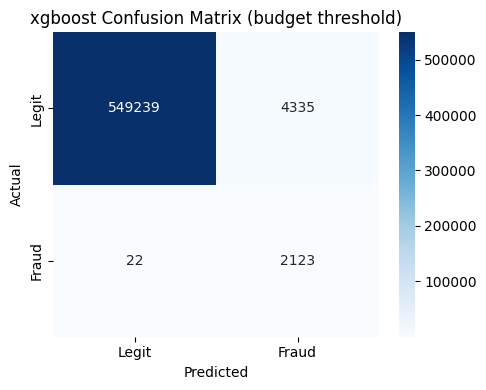

In [16]:
val_months = val['ts'].dt.to_period('M').nunique()
k_val = MONTHLY_BUDGET * val_months
budget_threshold = float(np.sort(val_probs)[::-1][k_val - 1])

precision_vals, recall_vals, thresholds = precision_recall_curve(y_val, val_probs)
f1_vals = 2 * precision_vals * recall_vals / np.clip(precision_vals + recall_vals, 1e-9, None)
f1_threshold = float(thresholds[np.nanargmax(f1_vals[:-1])])

test_months = test['ts'].dt.to_period('M').nunique()
for name, threshold in [('Budget', budget_threshold), ('F1-optimal', f1_threshold)]:
    preds = (test_probs >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, preds).ravel()
    logger.info(f'=== {name} threshold {threshold:.4f} ===')
    logger.info(f'Alerts per month: {(tp + fp) / test_months:,.0f}')
    logger.info(f'Precision: {precision_score(y_test, preds):.4f}')
    logger.info(f'Recall: {recall_score(y_test, preds):.4f}')
    logger.info(f'Missed fraud: {fn}')

preds = (test_probs >= budget_threshold).astype(int)
cm = confusion_matrix(y_test, preds)
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax, xticklabels=['Legit', 'Fraud'], yticklabels=['Legit', 'Fraud'])
ax.set_xlabel('Predicted')
ax.set_ylabel('Actual')
ax.set_title(f'{champion_name} Confusion Matrix (budget threshold)')
plt.tight_layout()
plt.show()

In [17]:
test['score'] = test_probs
fraud_df = test[test['is_fraud'] == 1].copy()
fraud_df['queued'] = fraud_df['score'] >= budget_threshold

card_summary = fraud_df.groupby('cc_num').agg(
    n_fraud=('is_fraud', 'size'),
    n_queued=('queued', 'sum'),
    first_fraud=('ts', 'min'),
    last_fraud=('ts', 'max')
)
card_summary['card_caught'] = card_summary['n_queued'] > 0
card_summary['span_days'] = (card_summary['last_fraud'] - card_summary['first_fraud']).dt.days

transaction_recall = fraud_df['queued'].mean()
card_recall = card_summary['card_caught'].mean()
fraud_on_caught_cards = fraud_df['cc_num'].map(card_summary['card_caught']).mean()

logger.info('=== Transaction vs Card Level Recall ===')
logger.info(f'Compromised cards in test: {len(card_summary)} | frauds per card: median {card_summary["n_fraud"].median():.0f}, max {card_summary["n_fraud"].max()}')
logger.info(f'Fraud episode length: median {card_summary["span_days"].median():.0f} days')
logger.info(f'Transaction-level recall (queued individually): {transaction_recall:.4f}')
logger.info(f'Card-level recall (card had at least one queued fraud): {card_recall:.4f}')
logger.info(f'Share of fraud on cards already under investigation: {fraud_on_caught_cards:.4f}')

missed_df = fraud_df[~fraud_df['queued']].copy()
missed_df['card_n_fraud'] = missed_df['cc_num'].map(card_summary['n_fraud'])
missed_df['card_n_queued'] = missed_df['cc_num'].map(card_summary['n_queued'])
logger.info(f'Missed frauds: {len(missed_df)}, all on cards with other queued fraud: {(missed_df["card_n_queued"] > 0).all()}')
missed_df[['ts', 'cc_num', 'amt', 'category', 'score', 'card_n_fraud', 'card_n_queued']].sort_values('ts')

2026-11-02 15:06:27,217 - INFO - === Transaction vs Card Level Recall ===
2026-11-02 15:06:27,218 - INFO - Compromised cards in test: 218 | frauds per card: median 10, max 19
2026-11-02 15:06:27,218 - INFO - Fraud episode length: median 1 days
2026-11-02 15:06:27,219 - INFO - Transaction-level recall (queued individually): 0.9897
2026-11-02 15:06:27,219 - INFO - Card-level recall (card had at least one queued fraud): 1.0000
2026-11-02 15:06:27,219 - INFO - Share of fraud on cards already under investigation: 1.0000
2026-11-02 15:06:27,222 - INFO - Missed frauds: 22, all on cards with other queued fraud: True


,ts,cc_num,amt,category,score,card_n_fraud,card_n_queued
66141,2020-07-13 23:57:54,3514897282719543,139.84,food_dining,0.000105,9,8
78185,2020-07-18 21:00:49,3534330126107879,21.38,personal_care,0.002916,12,11
105325,2020-07-27 21:20:53,4671727014157745,5.26,travel,0.000010,5,4
112806,2020-07-30 15:58:13,676173792455,19.02,health_fitness,0.000357,9,7
113423,2020-07-30 22:15:02,676173792455,9.25,travel,0.000107,9,7
133310,2020-08-06 22:21:18,6595970453799027,52.45,personal_care,0.002670,10,8
134726,2020-08-07 15:03:32,6595970453799027,52.82,personal_care,0.002025,10,8
141558,2020-08-09 23:12:26,4476840372112,20.36,kids_pets,0.001772,10,9
154719,2020-08-14 15:35:43,2254799658404120,21.42,health_fitness,0.001070,3,2
178388,2020-08-23 07:00:23,3518234918950662,1054.16,shopping_net,0.000768,2,1


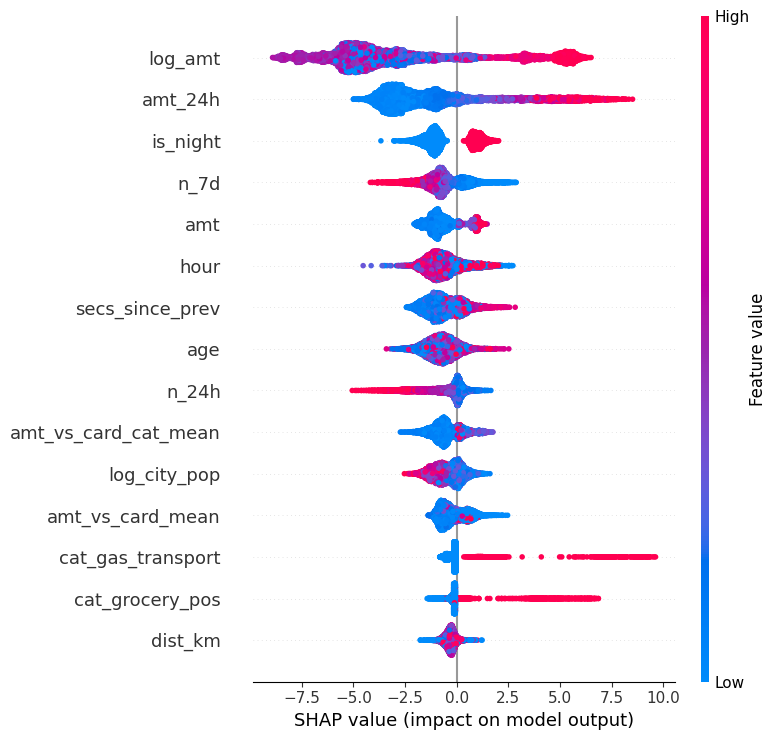

2026-11-02 15:06:29,507 - INFO - SHAP summary plot generated


In [18]:
explainer = shap.TreeExplainer(champion)

rng = np.random.default_rng(RANDOM_STATE)
fraud_idx = np.where(y_test == 1)[0]
legit_idx = rng.choice(np.where(y_test == 0)[0], size=8000, replace=False)
sample_idx = np.concatenate([fraud_idx, legit_idx])
X_shap = X_test_c.iloc[sample_idx]
shap_values = explainer.shap_values(X_shap)

shap.summary_plot(shap_values, X_shap, max_display=15, show=False)
plt.tight_layout()
plt.savefig('shap_summary_plot.png', bbox_inches='tight')
plt.show()

logger.info('SHAP summary plot generated')

2026-11-02 15:06:29,517 - INFO - Highest scoring transaction:
ts          2020-06-24 22:07:11
merchant     fraud_Bednar Group
category               misc_net
amt                      723.23
n_24h                       6.0
amt_24h                 1957.37
is_fraud                      1
Name: 11669, dtype: object
2026-11-02 15:06:29,517 - INFO - Score: 1.0000


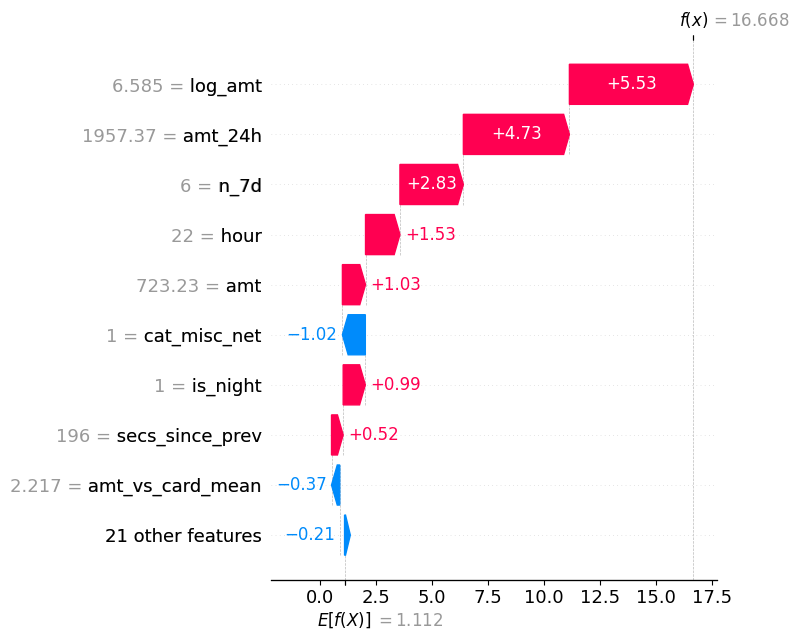

2026-11-02 15:06:30,038 - INFO - SHAP waterfall plot generated for a single fraud prediction


In [19]:
fraud_pos = int(np.argmax(test_probs))

logger.info(f'Highest scoring transaction:\n{test.loc[fraud_pos, ['ts', 'merchant', 'category', 'amt', 'n_24h', 'amt_24h', 'is_fraud']]}')
logger.info(f'Score: {test_probs[fraud_pos]:.4f}')

shap.plots.waterfall(explainer(X_test_c.iloc[[fraud_pos]])[0], max_display=10, show=False)
plt.tight_layout()
plt.savefig('shap_waterfall_plot.png', bbox_inches='tight')
plt.show()

logger.info('SHAP waterfall plot generated for a single fraud prediction')

In [20]:
def reference_bins(values):
    edges = np.unique(np.quantile(values, np.linspace(0, 1, 11)))
    counts = np.histogram(values, np.r_[-np.inf, edges[1:-1], np.inf])[0]
    return {'edges': edges.tolist(), 'pct': (counts / len(values)).tolist()}


fit_probs = champion.predict_proba(X_fit_c)[:, 1]
val_precision_at_budget = y_val[np.argsort(-val_probs)[:k_val]].mean()

config = {
    'champion': champion_name,
    'champion_version': int(model_version.version),
    'features': CHAMPION_FEATURES,
    'budget_threshold': budget_threshold,
    'f1_threshold': f1_threshold,
    'monthly_budget': MONTHLY_BUDGET,
    'random_audit': RANDOM_AUDIT,
    'precision_floor': round(float(val_precision_at_budget) * 0.8, 3),
    'ae_error_p99': float(np.quantile(ae_fit_err[legit_mask], 0.99)),
    'reference_bins': {f: reference_bins(X_fit_c[f].values) for f in CHAMPION_FEATURES if not f.startswith('cat_')},
    'score_bins': reference_bins(fit_probs),
    'reference_category': fit['category'].value_counts(normalize=True).to_dict(),
    'ks_features': ['amt', 'age', 'n_7d', 'amt_24h', 'secs_since_prev'],
}

with open('artifacts/config.json', 'w') as f:
    json.dump(config, f, indent=2)

fit[config['ks_features']].sample(20000, random_state=RANDOM_STATE).to_csv('artifacts/reference_sample.csv', index=False)

champion.save_model('artifacts/xgb_champion.json')
torch.save(autoencoder.state_dict(), 'artifacts/autoencoder.pt')
joblib.dump({'mu': scaler.mu, 'sd': scaler.sd}, 'artifacts/scaler.pkl')

logger.info(f'Champion model, autoencoder, scaler, config and KS reference sample saved | precision floor {config['precision_floor']}')

2026-11-02 15:06:30,912 - INFO - Champion model, autoencoder, scaler, config and KS reference sample saved | precision floor 0.308


In [21]:
test['score'] = test_probs
test['ae_err'] = ae_test_err
test['month'] = test['ts'].dt.to_period('M').astype(str)

simulation = []
for month, month_df in test.groupby('month'):
    days_present = month_df['ts'].dt.normalize().nunique()
    frac = days_present / pd.Period(month).days_in_month
    n_random = round(RANDOM_AUDIT * frac)
    n_top = round(MONTHLY_BUDGET * frac) - n_random

    month_df = month_df.sort_values('score', ascending=False)
    top_alerts = month_df.iloc[:n_top]
    random_audit = month_df.iloc[n_top:].sample(n_random, random_state=RANDOM_STATE)
    queue = pd.concat([top_alerts.assign(selection='top'), random_audit.assign(selection='random')])

    month_df[CHAMPION_FEATURES + ['category', 'score']].to_csv(f'scored/{month}.csv', index=False)
    queue[['trans_num', 'ts', 'cc_num', 'amt', 'score', 'selection', 'is_fraud']].to_csv(f'verdicts/{month}.csv', index=False)

    simulation.append({
        'month': month,
        'volume': len(month_df),
        'fraud': int(month_df['is_fraud'].sum()),
        'investigated': len(queue),
        'precision_top': top_alerts['is_fraud'].mean(),
        'random_hits': int(random_audit['is_fraud'].sum()),
        'recall': queue['is_fraud'].sum() / month_df['is_fraud'].sum(),
    })

simulation_df = pd.DataFrame(simulation).set_index('month')
logger.info(f'Monthly scoring and investigation queue simulated for {len(simulation_df)} months')
simulation_df.round(3)

2026-11-02 15:06:35,949 - INFO - Monthly scoring and investigation queue simulated for 7 months


,volume,fraud,investigated,precision_top,random_hits,recall
month,,,,,,
2020-06,30058,133,333,0.421,0,1.000
2020-07,85848,321,1000,0.333,0,0.984
2020-08,88759,415,1000,0.432,0,0.988
2020-09,69533,340,1000,0.354,0,0.988
2020-10,69348,384,1000,0.402,0,0.995
2020-11,72635,294,1000,0.306,0,0.990
2020-12,139538,258,1000,0.267,0,0.984


In [22]:
for month in simulation_df.index:
    print('=' * 60)
    !python monitor.py --month {month}

2026-11-02 15:06:38,743 - INFO - monitor.py v1.3 (2026-10-31) - KS/PSI/JS, pairs with fraud_detection.ipynb v1.3
2026-11-02 15:06:38,743 - INFO - 2020-06: 30,058 scored | 333 investigated
2026-11-02 15:06:38,743 - INFO - === Data Drift ===
2026-11-02 15:06:38,747 - INFO - KS amt                    D: 0.0113  p-value: 9.15e-02  No significant drift
2026-11-02 15:06:38,761 - INFO - KS age                    D: 0.0218  p-value: 2.22e-05  No significant drift
2026-11-02 15:06:38,771 - INFO - KS n_7d                   D: 0.1281  p-value: 3.53e-172  MARGINAL
2026-11-02 15:06:38,781 - INFO - KS amt_24h                D: 0.0946  p-value: 6.43e-94  MARGINAL
2026-11-02 15:06:38,792 - INFO - KS secs_since_prev        D: 0.0754  p-value: 8.43e-60  MARGINAL
2026-11-02 15:06:38,792 - INFO - PSI dow                    0.2381  Moderate shift - investigate
2026-11-02 15:06:38,799 - INFO - JS  category               0.0003  Very similar distributions
2026-11-02 15:06:38,799 - INFO - PSI computed for 16 

2026-11-02 15:06:43,699 - INFO - monitor.py v1.3 (2026-10-31) - KS/PSI/JS, pairs with fraud_detection.ipynb v1.3
2026-11-02 15:06:43,699 - INFO - 2020-07: 85,848 scored | 1000 investigated
2026-11-02 15:06:43,699 - INFO - === Data Drift ===
2026-11-02 15:06:43,703 - INFO - KS amt                    D: 0.0069  p-value: 4.20e-01  No significant drift
2026-11-02 15:06:43,723 - INFO - KS age                    D: 0.0281  p-value: 1.54e-11  No significant drift
2026-11-02 15:06:43,735 - INFO - KS n_7d                   D: 0.1187  p-value: 1.56e-199  MARGINAL
2026-11-02 15:06:43,751 - INFO - KS amt_24h                D: 0.0502  p-value: 6.26e-36  MARGINAL
2026-11-02 15:06:43,770 - INFO - KS secs_since_prev        D: 0.0363  p-value: 4.85e-19  No significant drift
2026-11-02 15:06:43,782 - INFO - JS  category               0.0000  Very similar distributions
2026-11-02 15:06:43,782 - INFO - PSI computed for 16 features | max 0.0797 (n_7d) | score 0.0041
2026-11-02 15:06:43,782 - INFO - === Mod

2026-11-02 15:06:48,554 - INFO - monitor.py v1.3 (2026-10-31) - KS/PSI/JS, pairs with fraud_detection.ipynb v1.3
2026-11-02 15:06:48,554 - INFO - 2020-08: 88,759 scored | 1000 investigated
2026-11-02 15:06:48,554 - INFO - === Data Drift ===
2026-11-02 15:06:48,559 - INFO - KS amt                    D: 0.0056  p-value: 6.82e-01  No significant drift
2026-11-02 15:06:48,577 - INFO - KS age                    D: 0.0306  p-value: 1.13e-13  No significant drift
2026-11-02 15:06:48,589 - INFO - KS n_7d                   D: 0.1138  p-value: 1.64e-184  MARGINAL
2026-11-02 15:06:48,606 - INFO - KS amt_24h                D: 0.0559  p-value: 8.08e-45  MARGINAL
2026-11-02 15:06:48,623 - INFO - KS secs_since_prev        D: 0.0451  p-value: 2.74e-29  No significant drift
2026-11-02 15:06:48,636 - INFO - JS  category               0.0000  Very similar distributions
2026-11-02 15:06:48,636 - INFO - PSI computed for 16 features | max 0.0719 (n_7d) | score 0.0042
2026-11-02 15:06:48,636 - INFO - === Mod

2026-11-02 15:06:53,474 - INFO - monitor.py v1.3 (2026-10-31) - KS/PSI/JS, pairs with fraud_detection.ipynb v1.3
2026-11-02 15:06:53,474 - INFO - 2020-09: 69,533 scored | 1000 investigated
2026-11-02 15:06:53,474 - INFO - === Data Drift ===
2026-11-02 15:06:53,478 - INFO - KS amt                    D: 0.0036  p-value: 9.85e-01  No significant drift
2026-11-02 15:06:53,495 - INFO - KS age                    D: 0.0362  p-value: 4.26e-18  No significant drift
2026-11-02 15:06:53,510 - INFO - KS n_7d                   D: 0.0584  p-value: 1.99e-46  MARGINAL
2026-11-02 15:06:53,528 - INFO - KS amt_24h                D: 0.0310  p-value: 1.92e-13  No significant drift
2026-11-02 15:06:53,546 - INFO - KS secs_since_prev        D: 0.0272  p-value: 2.05e-10  No significant drift
2026-11-02 15:06:53,547 - INFO - PSI dow                    0.1172  Moderate shift - investigate
2026-11-02 15:06:53,556 - INFO - JS  category               0.0000  Very similar distributions
2026-11-02 15:06:53,556 - INF

2026-11-02 15:06:58,514 - INFO - monitor.py v1.3 (2026-10-31) - KS/PSI/JS, pairs with fraud_detection.ipynb v1.3
2026-11-02 15:06:58,514 - INFO - 2020-10: 69,348 scored | 1000 investigated
2026-11-02 15:06:58,514 - INFO - === Data Drift ===
2026-11-02 15:06:58,519 - INFO - KS amt                    D: 0.0034  p-value: 9.94e-01  No significant drift
2026-11-02 15:06:58,536 - INFO - KS age                    D: 0.0372  p-value: 4.09e-19  No significant drift
2026-11-02 15:06:58,550 - INFO - KS n_7d                   D: 0.0851  p-value: 3.85e-98  MARGINAL
2026-11-02 15:06:58,565 - INFO - KS amt_24h                D: 0.0546  p-value: 1.12e-40  MARGINAL
2026-11-02 15:06:58,584 - INFO - KS secs_since_prev        D: 0.0353  p-value: 3.39e-17  No significant drift
2026-11-02 15:06:58,591 - INFO - PSI n_7d                   0.1165  Moderate shift - investigate
2026-11-02 15:06:58,596 - INFO - JS  category               0.0000  Very similar distributions
2026-11-02 15:06:58,596 - INFO - PSI comp

2026-11-02 15:07:03,447 - INFO - monitor.py v1.3 (2026-10-31) - KS/PSI/JS, pairs with fraud_detection.ipynb v1.3
2026-11-02 15:07:03,447 - INFO - 2020-11: 72,635 scored | 1000 investigated
2026-11-02 15:07:03,447 - INFO - === Data Drift ===
2026-11-02 15:07:03,451 - INFO - KS amt                    D: 0.0047  p-value: 8.73e-01  No significant drift
2026-11-02 15:07:03,468 - INFO - KS age                    D: 0.0373  p-value: 2.31e-19  No significant drift
2026-11-02 15:07:03,481 - INFO - KS n_7d                   D: 0.0859  p-value: 4.47e-101  MARGINAL
2026-11-02 15:07:03,500 - INFO - KS amt_24h                D: 0.0234  p-value: 6.82e-08  No significant drift
2026-11-02 15:07:03,504 - INFO - KS secs_since_prev        D: 0.0076  p-value: 3.25e-01  No significant drift
2026-11-02 15:07:03,511 - INFO - PSI n_7d                   0.1081  Moderate shift - investigate
2026-11-02 15:07:03,516 - INFO - JS  category               0.0000  Very similar distributions
2026-11-02 15:07:03,516 - IN

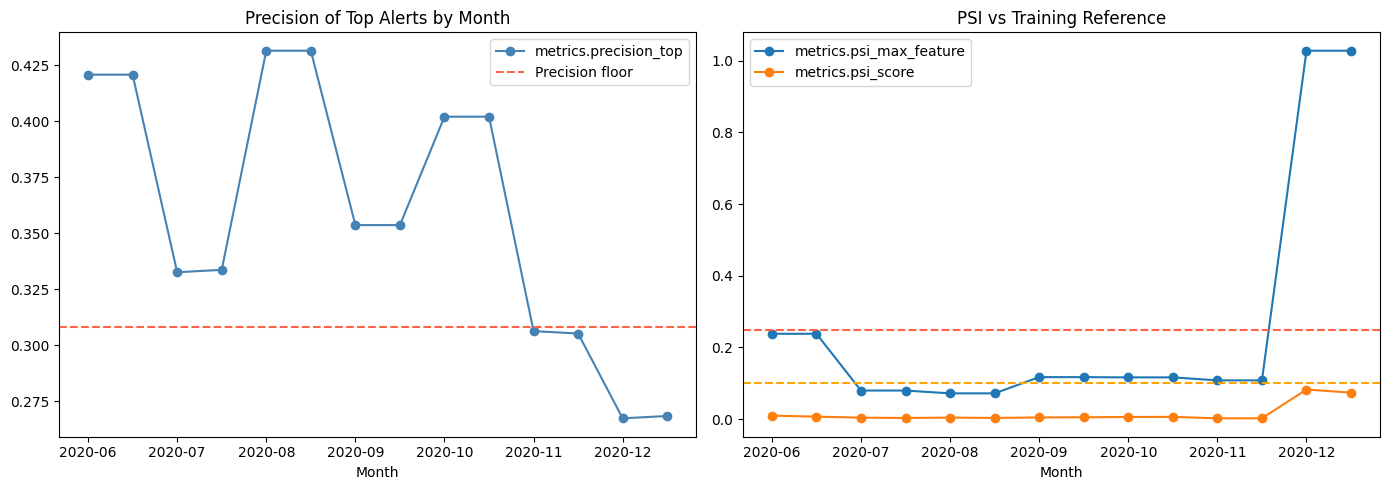

,params.month,metrics.precision_top,metrics.psi_max_feature,metrics.psi_score,metrics.js_category,metrics.random_audit_fraud_rate,tags.alarms
6,2020-06,0.420886,0.238142,0.009620,0.000302,0.0,none
13,2020-06,0.420886,0.238142,0.006945,0.000302,0.0,none
5,2020-07,0.332632,0.079723,0.004090,0.000033,0.0,none
12,2020-07,0.333684,0.079723,0.003178,0.000033,0.0,none
4,2020-08,0.431579,0.071877,0.004189,0.000018,0.0,none
11,2020-08,0.431579,0.071877,0.003219,0.000018,0.0,none
3,2020-09,0.353684,0.117160,0.004616,0.000027,0.0,none
10,2020-09,0.353684,0.117160,0.005163,0.000027,0.0,none
2,2020-10,0.402105,0.116452,0.005892,0.000025,0.0,none
9,2020-10,0.402105,0.116452,0.006315,0.000025,0.0,none


In [23]:
monitoring_runs = mlflow.search_runs(experiment_names=['fraud-monitoring']).sort_values('params.month')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

monitoring_runs.plot(x='params.month', y='metrics.precision_top', marker='o', ax=axes[0], color='steelblue', legend=False)
axes[0].axhline(config['precision_floor'], color='tomato', linestyle='--', label='Precision floor')
axes[0].set_title('Precision of Top Alerts by Month')
axes[0].set_xlabel('Month')
axes[0].legend()

monitoring_runs.plot(x='params.month', y=['metrics.psi_max_feature', 'metrics.psi_score'], marker='o', ax=axes[1])
axes[1].axhline(0.25, color='tomato', linestyle='--')
axes[1].axhline(0.10, color='orange', linestyle='--')
axes[1].set_title('PSI vs Training Reference')
axes[1].set_xlabel('Month')

plt.tight_layout()
plt.show()

monitoring_runs[['params.month', 'metrics.precision_top', 'metrics.psi_max_feature', 'metrics.psi_score', 'metrics.js_category', 'metrics.random_audit_fraud_rate', 'tags.alarms']]

In [24]:
def mean_abs_shap(X, n=5000):
    X_sample = X.sample(min(n, len(X)), random_state=RANDOM_STATE)
    return pd.Series(np.abs(explainer.shap_values(X_sample)).mean(axis=0), index=X.columns)


reference_shap = mean_abs_shap(X_val_c)
top5_features = reference_shap.sort_values(ascending=False).index[:5]

shap_by_month = pd.DataFrame({month: mean_abs_shap(X_test_c[test['month'].values == month]) for month in simulation_df.index})
shap_shift = (shap_by_month.loc[top5_features].div(reference_shap[top5_features], axis=0) - 1)

logger.info(f'Relative change in mean |SHAP| for top 5 features vs validation:\n{shap_shift.round(2)}')
logger.info(f'Model drift alarm (>30% shift in any top 5 feature): {(shap_shift.abs() > 0.30).any().to_dict()}')

2026-11-02 15:07:11,842 - INFO - Relative change in mean |SHAP| for top 5 features vs validation:
          2020-06  2020-07  2020-08  2020-09  2020-10  2020-11  2020-12
log_amt     -0.02     0.01     0.01     0.01     0.01    -0.00    -0.03
amt_24h     -0.09    -0.07    -0.07    -0.00     0.01    -0.01    -0.26
is_night     0.01    -0.01    -0.00    -0.01    -0.00     0.00     0.01
amt         -0.02     0.00     0.01     0.01     0.01     0.00    -0.03
hour         0.02     0.01     0.01     0.01    -0.00     0.00     0.03
2026-11-02 15:07:11,842 - INFO - Model drift alarm (>30% shift in any top 5 feature): {'2020-06': False, '2020-07': False, '2020-08': False, '2020-09': False, '2020-10': False, '2020-11': False, '2020-12': False}
